# 07 不確かさ解析: s の符号はデータのばらつきで反転するか

方針（A＋D の組み合わせ）
1. **フィットだけをブートストラップ**（追従車単位・追従タイプごとに引き直し）→ 自由パラメータ θ2(車), ρc(トラック), a2, b1 の ± と連動(共分散)
2. **方法A（誤差伝播）**：各 (ρ1, ρ2) で s を数値微分 → s の ± と「どのパラメータ由来か」の内訳
3. **方法D（全体ブートストラップ）**：1 の各回のパラメータで s を計算し直し → P(s>0)。2 と答え合わせ

- 引き直すのはフィット用の追従データ（df_final 由来）だけ。マクロデータは s を「どこで読むか」なので固定
- フィットの設定は strong_constraint と同じ（ub, uf, ρc, θ1(車) と uf(トラック) は論文値に固定）
- ここで出る ± は「データのばらつき（①偶然的）」だけ。Eq.7 の版・固定値の選び方などはシナリオ比較で別に扱う

In [1]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

sys.path.append(os.path.abspath('..'))
from src.whole_pipeline import prepare_data, filter_invalid_headway, compute_micro_density
from src.sensitivity_scaling import pipeline_step3
from src.uncertainty import *

OUT_DIR = os.path.abspath(os.path.join('..', 'results', 'uncertainty_2026-10-27'))
os.makedirs(OUT_DIR, exist_ok=True)
def save(fig, name):
    fig.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches='tight')

SCALINGS = ['printed', 'inverted']
B = 1000          # ブートストラップ回数（1回 ≈ 1秒強。まず 200 で試すのもあり）
SEED = 0

## 0. データ準備（1回だけ）

In [2]:
data = prepare_data()
df_mdensity = compute_micro_density(filter_invalid_headway(data['df_final']))   # Step 1 と同じ前処理
fd = prepare_fit_data(df_mdensity)   # 引き直しの単位 = time_period × Vehicle_ID（追従車）

(4566387, 19)

--フリッカリング除去--
補正されたブロック数: 671
行数: 4,566,387

--フリッカリング除去--
補正されたブロック数: 142
行数: 4,566,387

--フリッカリング補正行の車間距離を座標から再計算--
対象行: 3,225  再計算できた行: 2,472  NaNにした行: 753
  NaNの内訳: 先行車が別車線 345行 / 先行車なし・位置不明・距離0以下 408行
  元の値から1ft超変わった行: 2,284  (元の値が0だった行: 208)

--ペアIDを付与--
総行数: 4,566,387
追従ペア数: 13,827

--モードID別を付与--
総行数: 4,566,387
追従ペア数: 13,827
mode_id
1.0    12337
2.0      438
3.0      549
4.0       42
5.0      461
dtype: int64

--追従していない軌跡データを削除--
フィルタ前の行数: 4,566,387
フィルタ後の行数: 4,359,245
除外された行数: 207,142
ペア数: 13,827

--車線フィルタ(2,3,4レーンを残す)--
フィルタ前: 4,359,245行
フィルタ後: 2,338,830行
除外された行数: 2,020,415行
追従ペア数: 5,780

車線の分布:
Lane_ID
2.0    800339
3.0    689350
4.0    849141
Name: count, dtype: int64

--車種フィルタ(1,2,3,4の追従モードを残す)--
フィルタ前のペア数: 5,780
フィルタ後のペア数: 5,666
除外されたペア数: 114
フィルタ後行数: 2,335,438行

モードID別ペア数:
mode_id
1.0    5067
2.0     237
3.0     326
4.0      36
dtype: int64

--追従時間フィルタ--
フィルタ前のペア数: 5,666
フィルタ後のペア数: 1,570
除外されたペア数: 4,096
フィルタ前の行数: 2,335,438
フィルタ後の行数: 1,487,854

--カットオフウィンドウ-

In [3]:
# s を読む場所: 観測スナップショット（notebook 05/06 と同じ集合。ここでは rho1, rho2 だけ使う）
paper_car = {'ub': 12.762, 'uf': 118.367, 'rhoc': 12.676, 'theta1': 4.995, 'theta2': 0.2309}
paper_trk = {'uf': 68.478, 'rhoc': 25.936}
states = pipeline_step3(data, paper_car, paper_trk, 1.0, 1.0, 'printed',
                        skip_sec_warmup=100, skip_sec_cooldown=100)
states_both = states[(states['rho1'] > 0) & (states['rho2'] > 0)].reset_index(drop=True)
grid = make_grid(rho1_max=80, rho2_max=8)
len(states_both)

各time_periodの最初の100秒を除外: 11,790件 → 10,846件
各time_periodの最後の100秒を除外: 10,846件 → 10,005件
1-pipe速度を計算(scaling=printed): 5,046スナップショット中、5,046件で解を取得
最小道路占有を計算: 5,046スナップショット中、5,046件で計算完了
協力余剰sを計算: 5,046スナップショット中、5,046件で計算完了（うちs>0: 2,130件）


4959

## 1. 推定方法の確認

ISRES の代わりに1次元探索（格子→黄金分割）を使うので、元の推定（ISRES, 学習7割）と一致するか確認する。
ブートストラップでは全データ（引き直した全行）で推定するので、基準値 `ref` も全データでの推定にそろえる。

In [4]:
isres = {'car_theta2': 0.343, 'truck_rhoc': 18.542, 'a2': 0.4687, 'b1': 1.8331}   # results_*_strong_constraint
display(check_reference_fit(fd, isres))
ref = fit_all(fd)
ref

,ISRES (元の推定),今回の方法・学習7割,今回の方法・全データ
car_theta2,0.3430,0.343240,0.343319
truck_rhoc,18.5420,18.541167,18.554621
a2,0.4687,0.471978,0.472050
b1,1.8331,1.832994,1.832365


{'car_theta2': np.float64(0.3433191543959445),
 'truck_rhoc': np.float64(18.55462139408364),
 'a2': np.float64(0.47205004635200204),
 'b1': np.float64(1.8323646825837323)}

## 2. 手順1: フィットのブートストラップ（結果はCSVに保存し、あれば読み込む）

In [5]:
path = os.path.join(OUT_DIR, f'boot_params_B{B}_seed{SEED}.csv')
if os.path.exists(path):
    df_boot = pd.read_csv(path)
else:
    df_boot = bootstrap_fit(fd, B=B, seed=SEED)
    df_boot.to_csv(path, index=False)
display(summarize_boot_params(df_boot, ref).round(4))
cov = df_boot[list(FREE_PARAMS)].cov().values
df_boot[list(FREE_PARAMS)].corr().round(2)   # パラメータどうしの連動（相関係数）

  100/1000
  200/1000
  300/1000
  400/1000
  500/1000
  600/1000
  700/1000
  800/1000
  900/1000
  1000/1000


,ref,boot_mean,sd (±),q2.5,q97.5,at_bound_rate,sd/ref
car_theta2,0.3433,0.3437,0.0048,0.3343,0.3535,0.0,0.0140
truck_rhoc,18.5546,19.5109,3.6543,17.0415,29.5160,0.0,0.1969
a2,0.4721,0.4726,0.0392,0.4003,0.5490,0.0,0.0831
b1,1.8324,1.7692,0.2251,1.1132,2.0880,0.0,0.1228


,car_theta2,truck_rhoc,a2,b1
car_theta2,1.00,0.00,0.08,0.00
truck_rhoc,0.00,1.00,-0.00,-0.83
a2,0.08,-0.00,1.00,0.03
b1,0.00,-0.83,0.03,1.00


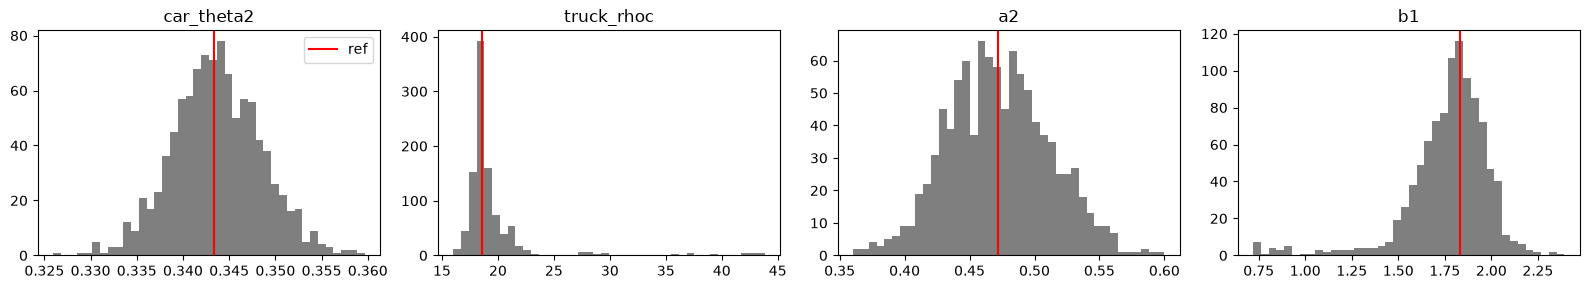

In [6]:
fig, axs = plt.subplots(1, len(FREE_PARAMS), figsize=(4 * len(FREE_PARAMS), 3))
for ax, k in zip(axs, FREE_PARAMS):
    ax.hist(df_boot[k], bins=40, color='tab:gray')
    ax.axvline(ref[k], color='r', lw=1.5, label='ref')
    ax.set_title(k)
axs[0].legend()
fig.tight_layout()
save(fig, 'u1_param_hist.png')
plt.show()

見るところ
- `sd/ref`: 相対的な ±。台数の少ない T-T（6台）から推定する truck_rhoc は大きくなりやすい
- `at_bound_rate`: 探索範囲の端に張り付いた割合。大きければ ± は過小評価（データだけでは決まっていない）
- 相関: a2 は θ2 を、b1 は truck_rhoc を使って推定するので連動しうる

## 3. 手順2・3: 格子上で方法A と 方法D

In [7]:
resA, resD = {}, {}
for sc in SCALINGS:
    resA[sc] = delta_method(ref, cov, grid['R1'], grid['R2'], sc)
    resD[sc] = summarize_boot_surplus(bootstrap_surplus(df_boot, grid['R1'], grid['R2'], sc))

rows = []
for sc in SCALINGS:
    for name, r in [('A (delta)', resA[sc]), ('D (bootstrap)', resD[sc])]:
        c = pd.Series(sign_class(r['p_pos']).ravel()).value_counts(normalize=True)
        rows.append({'scaling': sc, 'method': name, 'sd_median': np.nanmedian(r['sd']), **c.to_dict()})
pd.DataFrame(rows).round(3)

,scaling,method,sd_median,ambiguous,robust -,robust +
0,printed,A (delta),0.033,0.852,0.148,NaN
1,printed,D (bootstrap),0.027,0.874,0.126,NaN
2,inverted,A (delta),0.053,0.018,NaN,0.982
3,inverted,D (bootstrap),0.044,NaN,NaN,1.000


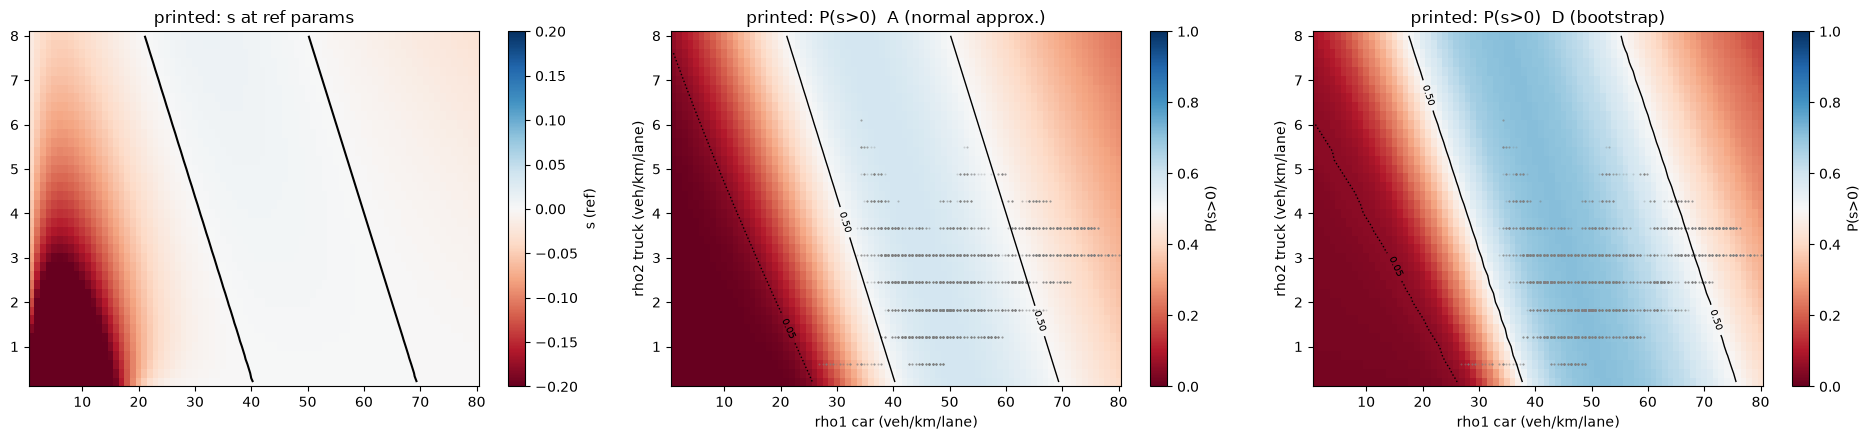

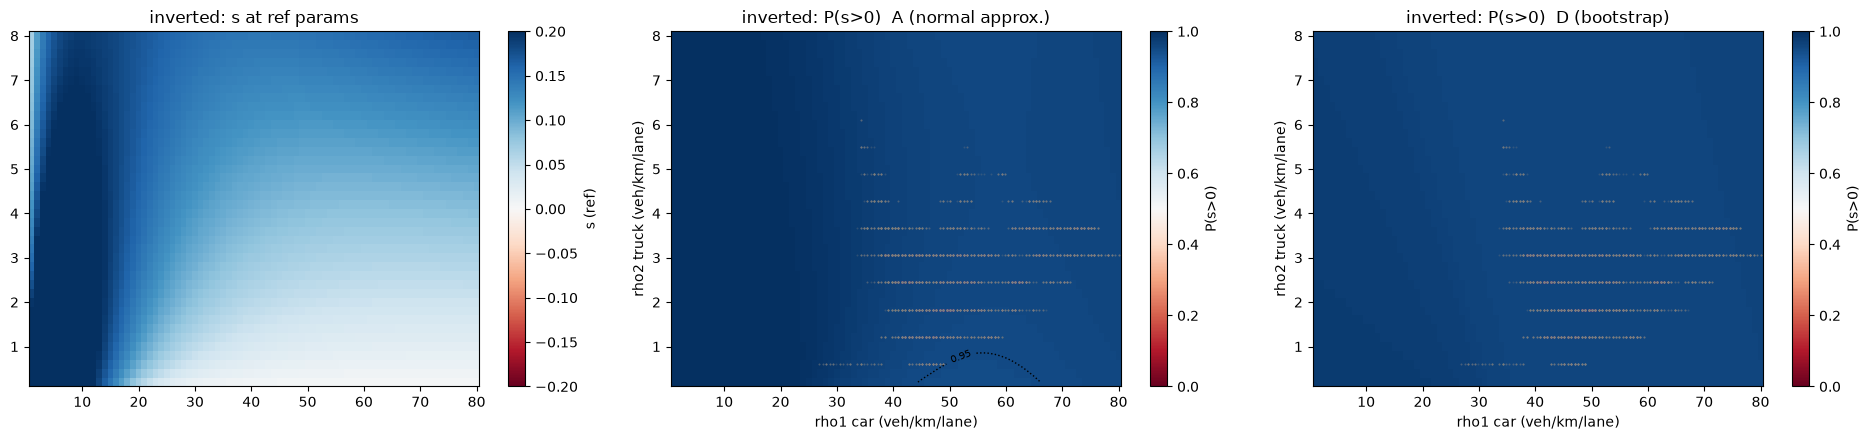

In [8]:
for sc in SCALINGS:
    fig, axs = plt.subplots(1, 3, figsize=(19, 4.5))
    m = axs[0].pcolormesh(grid['rho1'], grid['rho2'], resA[sc]['s'], cmap='RdBu',
                          vmin=-0.2, vmax=0.2, shading='auto')
    axs[0].contour(grid['rho1'], grid['rho2'], resA[sc]['s'], levels=[0], colors='k')
    plt.colorbar(m, ax=axs[0], label='s (ref)')
    axs[0].set_title(f'{sc}: s at ref params')
    plot_p_pos_map(grid, resA[sc]['p_pos'], ax=axs[1], title=f'{sc}: P(s>0)  A (normal approx.)', states=states_both)
    plot_p_pos_map(grid, resD[sc]['p_pos'], ax=axs[2], title=f'{sc}: P(s>0)  D (bootstrap)', states=states_both)
    fig.tight_layout()
    save(fig, f'u2_p_pos_map_{sc}.png')
    plt.show()

### 方法A の内訳: s の ± はどのパラメータ由来か

`share_k = g_k (Σg)_k / Var(s)`。合計1。負の値は「他のパラメータとの連動で打ち消し合っている」分。

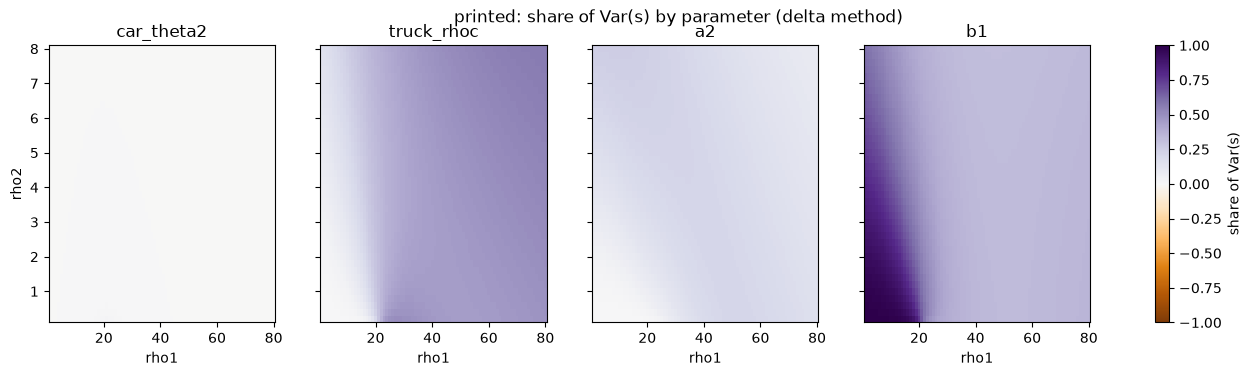

printed 内訳の中央値: {'car_theta2': -0.0, 'truck_rhoc': 0.453, 'a2': 0.184, 'b1': 0.346}


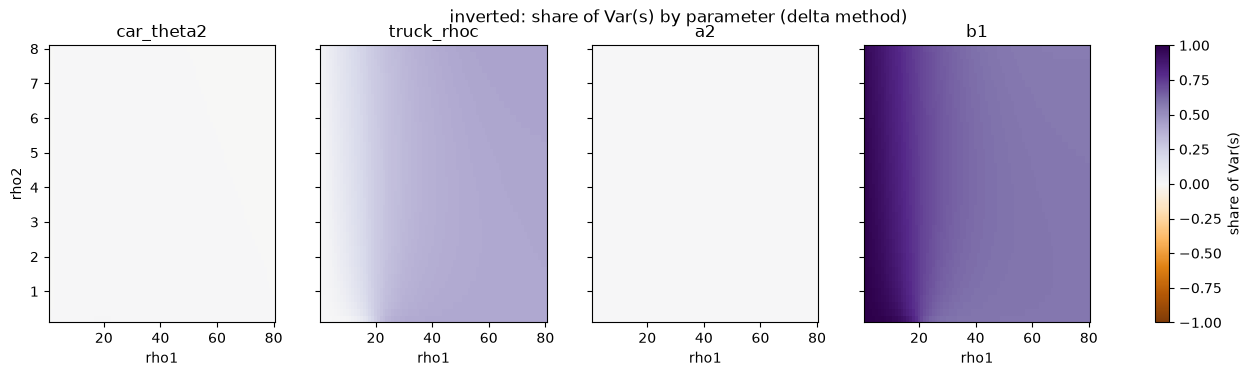

inverted 内訳の中央値: {'car_theta2': 0.0, 'truck_rhoc': 0.388, 'a2': 0.003, 'b1': 0.609}


In [9]:
for sc in SCALINGS:
    fig = plot_share_maps(grid, resA[sc]['share'], title=f'{sc}: share of Var(s) by parameter (delta method)')
    save(fig, f'u3_share_{sc}.png')
    plt.show()
    print(sc, '内訳の中央値:', {k: round(float(np.nanmedian(s)), 3) for k, s in zip(FREE_PARAMS, resA[sc]['share'])})

### A と D の答え合わせ

点が赤い対角線に乗っていれば、方法A（直線近似＋正規分布）で十分 → 内訳の説明をそのまま使える。
ずれる場所は、s がパラメータに対して曲がっている・u* が解けない回がある、など。

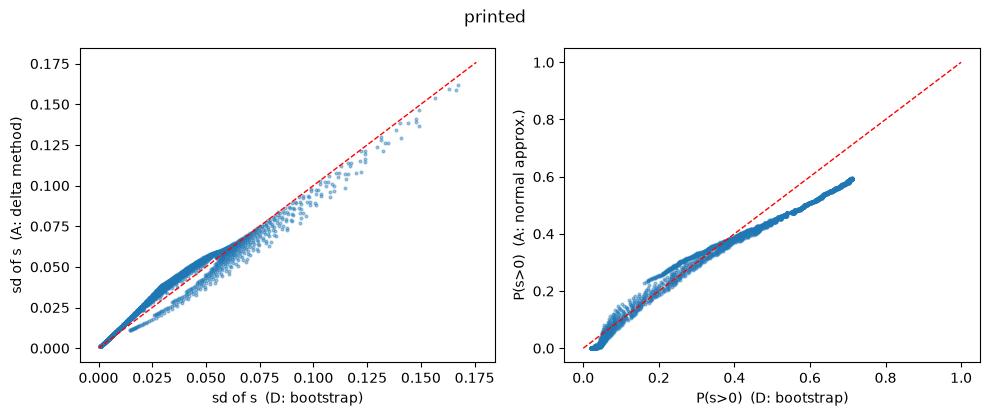

printed: sd比 A/D の中央値 1.22,  連動を無視したAとの比 0.80,  u*が解けなかった回がある格子点 0.0%


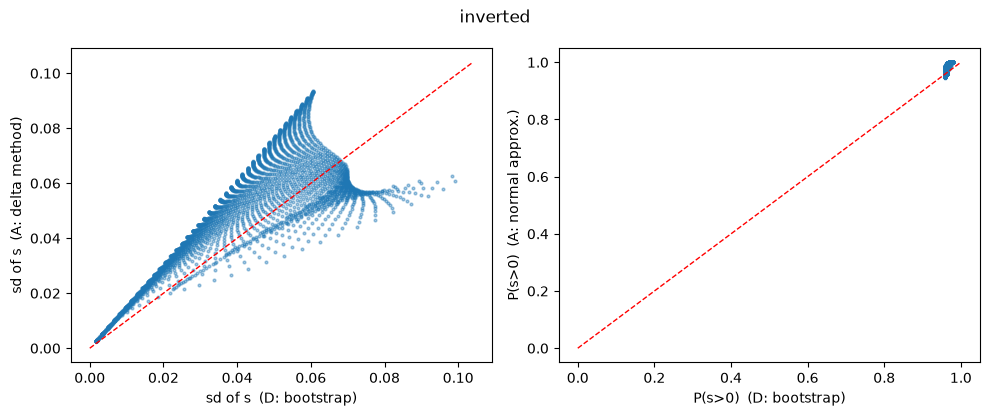

inverted: sd比 A/D の中央値 1.39,  連動を無視したAとの比 0.75,  u*が解けなかった回がある格子点 0.0%


In [10]:
for sc in SCALINGS:
    fig = plot_compare_A_D(resA[sc], resD[sc], title=sc)
    save(fig, f'u4_compare_A_D_{sc}.png')
    plt.show()
    sa, sd_ = resA[sc]['sd'], resD[sc]['sd']
    print(f"{sc}: sd比 A/D の中央値 {np.nanmedian(sa / sd_):.2f},  "
          f"連動を無視したAとの比 {np.nanmedian(resA[sc]['sd_indep'] / sa):.2f},  "
          f"u*が解けなかった回がある格子点 {np.mean(resD[sc]['solved_rate'] < 1):.1%}")

## 4. 観測スナップショットでの符号の頑健さ

In [11]:
r1, r2 = states_both['rho1'].values, states_both['rho2'].values
obs_rows = []
for sc in SCALINGS:
    A = delta_method(ref, cov, r1, r2, sc)
    D = summarize_boot_surplus(bootstrap_surplus(df_boot, r1, r2, sc))
    states_both[f's_ref_{sc}'] = A['s']
    states_both[f'p_pos_A_{sc}'] = A['p_pos']
    states_both[f'p_pos_D_{sc}'] = D['p_pos']
    for name, p in [('A', A['p_pos']), ('D', D['p_pos'])]:
        c = pd.Series(sign_class(p)).value_counts(normalize=True)
        obs_rows.append({'scaling': sc, 'method': name, 'n': len(p),
                         'frac_s_pos_ref': np.nanmean(A['s'] > 0), **c.to_dict()})
pd.DataFrame(obs_rows).round(3)

,scaling,method,n,frac_s_pos_ref,ambiguous,robust +
0,printed,A,4959,0.807,1.0,NaN
1,printed,D,4959,0.807,1.0,NaN
2,inverted,A,4959,1.000,NaN,1.0
3,inverted,D,4959,1.000,NaN,1.0


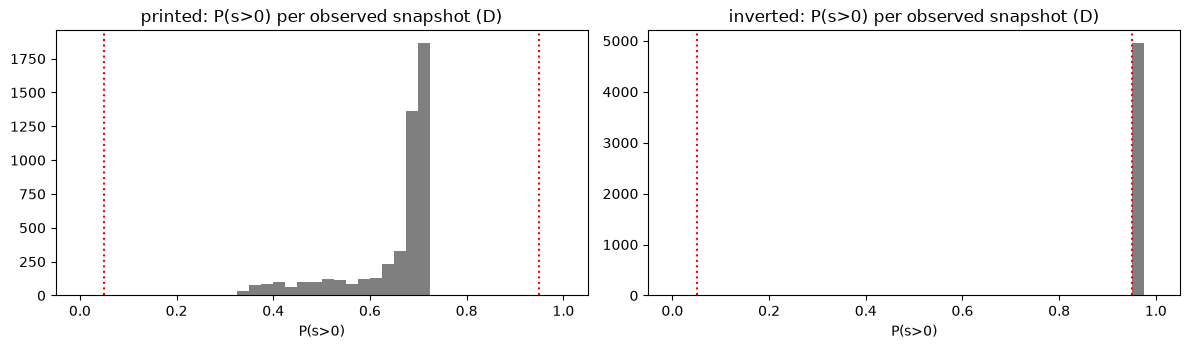

In [12]:
fig, axs = plt.subplots(1, len(SCALINGS), figsize=(6 * len(SCALINGS), 3.6))
for ax, sc in zip(axs, SCALINGS):
    ax.hist(states_both[f'p_pos_D_{sc}'].dropna(), bins=np.linspace(0, 1, 41), color='tab:gray')
    for x in (0.05, 0.95):
        ax.axvline(x, color='r', ls=':')
    ax.set_title(f'{sc}: P(s>0) per observed snapshot (D)')
    ax.set_xlabel('P(s>0)')
fig.tight_layout()
save(fig, 'u5_obs_p_pos_hist.png')
plt.show()

## メモ（解釈の注意）

- ここでの ± は「どの車がサンプルに入ったか」によるばらつきだけ。固定した値（ub, uf, ρc, θ1, トラックの uf）は動かしていないので、それらの不確かさは含まない → 固定を外す・論文値以外にする、はシナリオ比較で
- printed と inverted の差（Eq.7 の版）はモデルの不確かさ。上の表を並べて「データのばらつきで反転するか」と「式の選び方で反転するか」を分けて書く
- a2, b1 は Eq.20 の形 f(ρ/a) で推定している。inverted で使うのは推定の前提と整合しない（2026-10-03 のメモ参照）
- T-T は6台、T-C は47台、C-T は65台しかないので、トラック側のパラメータの ± が大きくなるのは自然。台数が少ないとブートストラップの ± 自体の精度も落ちる
- 追従タイプごとに独立に引き直している（層別）。同じ車が複数の追従タイプに出てくる場合の連動は無視している